In [133]:
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm

import matplotlib as mpl
import matplotlib.ticker as ticker

warnings.filterwarnings('ignore') # Suppress all warnings (use with caution)

In [134]:
# Global configuration for plot titles and labels
mpl.rcParams['figure.titlesize'] = 18         # Main figure title size
mpl.rcParams['axes.titlesize'] = 16           # Axis title size
mpl.rcParams['axes.titleweight'] = 'bold'     # Axis title weight
mpl.rcParams['axes.labelsize'] = 14           # Axis label size
mpl.rcParams['axes.labelweight'] = 'normal'   # Axis label weight

In [135]:
#Config1
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1\ELPI+\20250916\Blanc sans rotation\file01.dat' # blanc sans rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1\ELPI+\20250916\Blanc avec rotation\file02.dat' # blanc avec rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1\ELPI+\20250916\RIB-PS\file03.dat' # RIB-PS
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1\ELPI+\20250916\Blanc avec rotation_fin\file04.dat' # blanc avec rotation end

#Config1_rep2
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1_rep2\ELPI+\20250917\Blanc sans rotation\file02.dat' # blanc sans rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1_rep2\ELPI+\20250917\Blanc avec rotation\file03.dat' # blanc avec rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1_rep2\ELPI+\20250917\RIB-PS\file04.dat' # RIB-PS
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1_rep2\ELPI+\20250917\Blanc avec rotation_end\file05.dat' # blanc avec rotation end

#Config2
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config2\ELPI+\19-09-2025\Blanc sans rotation\file01.dat' # blanc sans rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config2\ELPI+\19-09-2025\Blanc avec rotation\file02.dat' # blanc avec rotation
file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config2\ELPI+\19-09-2025\RIB-PS\file03.dat' # RIB-PS
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config2\ELPI+\19-09-2025\Blanc avec rotation_end\file04.dat' # blanc avec rotation end

##### Plots title

In [136]:
#Config1
# n = "Config1_Blank_without_rotation"
# n = "Config1_Blank_with_rotation"
# n = "Config1_RIB-PS"  
# n = "Config1_Blank_with_rotation_end"

#Config1_rep2
# n = "Config1_rep2_Blank_without_rotation"
# n = "Config1_rep2_Blank_with_rotation"
# n = "Config1_rep2_RIB-PS"  
# n = "Config1_rep2_Blank_with_rotation_end" 

#Config2 
# n = "Config2_Blank_without_rotation"
# n = "Config2_Blank_with_rotation"
n = "Config2_RIB-PS"  
# n = "Config2_Blank_with_rotation_end"       

In [137]:
speed_correction = 210 # Channel1: Speed: Volt --> RPM
pressure_correction = 1 # Channel2: Pressure: Volt --> bar
temperature_correction = 100 # Channel3: Temperature: Volt --> °C

##### Physical Data (Dp) & measured raw data in current (fA) {1 femtoampere = 10^-15 ampere}

In [138]:
# Read channel info from the file header
with open(file, 'r') as f:
    content=f.read().split('\n')
 # Extract channel info from line 13
    physical_channels = np.array(content[12].split('=')[-1].split(',')).astype(float)

# Read physical data from CSV, select columns 0 and 2-15
physical_data = pd.read_csv(file,sep=',',header=36, usecols=np.append([0],np.arange(2,16,1)), index_col=0)

# Assign channel names (skip first beacause we have 15 physical_channels and 14 physical data)
physical_data.columns=physical_channels[1:]
physical_data.dropna(inplace=True)

# Convert index to datetime
physical_data.index = pd.to_datetime(physical_data.index, errors='coerce')
physical_data.index.names =['DateTime']
physical_data.reset_index(drop=False, inplace=True)

# Calculate elapsed time in seconds
physical_data['Time [s]'] = (physical_data['DateTime'] - physical_data['DateTime'].iloc[0]).dt.total_seconds()

#### All channels (500#) and measured concentrations

In [139]:
columns = np.append([0],np.arange(22,25,1)) # Selecting of: Channel1: Speed Channel2:Pressure Channel3: Temperature
columns = np.append(columns,[36]) # Selecting of: Total number concentration
columns = np.append(columns,np.arange(38,538,1)) # Selecting of: Normalized number concentration from 1 to 500

In [140]:
# Load data
data = pd.read_csv(file, sep=',', header=36, usecols=columns, index_col=0)
data.dropna(inplace=True)

# Convert index to datetime
# data.index = pd.to_datetime(data.index, errors='coerce') # for unknown format
# data.index = pd.to_datetime(data.index, format='%Y/%m/%d %H:%M:%S.%f') # for 10Hz frequency
data.index = pd.to_datetime(data.index, format='%Y/%m/%d %H:%M:%S') # for 1Hz frequency

data.index.names =['DateTime']
data.reset_index(drop=False, inplace=True)

# Rename columns for clarity
data.rename(columns={data.columns[1]:'Speed',data.columns[2]:'Pressure',data.columns[3]:'Temperature'}, inplace=True) 

# Apply correction factors
data['Speed'] = data['Speed']*speed_correction 
data['Pressure'] = data['Pressure']*pressure_correction 
data['Temperature'] = data['Temperature']*temperature_correction 

# Calculate elapsed time
data['Time [s]'] = (data['DateTime'] - data['DateTime'].iloc[0]).dt.total_seconds()

##### Plot: Raw data in current (fA) vs time and Dp

In [141]:
# fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw={'width_ratios':(1,0.5), 'wspace':0.1})
# fig.set_size_inches(w=30, h=8)

# fig.suptitle(f"{n}")

# ax1.plot(physical_data['Time [s]'], physical_data[physical_data.columns[1:-1]].sum(axis=1))
# ax1.set_ylabel('Total instantaneous current [fA]')
# ax1.set_xlabel('Time [s]')
# ax1.grid(alpha=0.2)
# ax1.set_xlim(left=0)
# ax1.set_ylim(bottom=0)
# ax1.margins(x=0)
# # ax1.set_xlim(200,2000)


# # Pour l'axe y de ax1 en notation scientifique
# ax1.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# ax2.bar(physical_data.columns[1:-1].astype(float)*1000, height= physical_data[physical_data.columns[1:-1]].sum(axis=0),width=1000* physical_data.columns[1:-1].astype(float)/5 )
# ax2.set_xscale('log')
# ax2.set_xmargin(0)
# ax2.grid(alpha=0.2)
# ax2.set_ylabel('Instantaneous current [fA]')
# ax2.set_xlabel('Particles Dia. [nm]')
# ax2.set_yscale('log')
# # Pour l'axe y de ax2 en notation scientifique
# ax2.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
# ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# # Ajout des étiquettes de diamètre sur chaque barre
# for bar, diameter in zip(ax2.patches, physical_data.columns[1:-1].astype(float) * 1000):
#     height = bar.get_height()
#     if height > 0:  # éviter log(0)
#         ax2.text(
#             bar.get_x() + bar.get_width() / 2,
#             height * 1.1,
#             f"{diameter:.0f} nm",
#             ha='center',
#             va='bottom',
#             fontsize=10,
#             rotation=90
#         )

##### Plot: Total number concentration [#/cm3] vs time

In [142]:
# fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, sharex=True, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
# fig.set_size_inches(w=25, h=15)

# fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# # Définir les limites communes de l'axe X
# time_min = 0
# time_max = 3500

# ax1.plot(data['Time [s]'], data[data.columns[4]])
# ax1.vlines(x=40, ymin=ax1.get_ylim()[0], ymax=ax1.get_ylim()[1], color='gray', linestyle='--')
# ax1.set_ylabel('Number concentration [#/cm3]')
# ax1.set_xlabel('Time [s]')
# ax1.grid(alpha=0.2)
# ax1.margins(x=0)
# # ax1.set_yscale('log')
# ax1.set_ylim(bottom=1E3, top=3E4)
# # ax1.set_xlim(left=0)

# ax2_1 = ax2.twinx()
# ax2_2 = ax2.twinx()

# ax2.set_xlim(time_min, time_max)
# ax2.plot(data['Time [s]'], data['Speed']*(80/500), color='tab:blue') # RPM -> km/h
# ax2.vlines(x=40, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--')
# # ax2_1.plot(data['Time [s]'], data['Pressure'], color='tab:green')
# # ax2_2.plot(data['Time [s]'], data['Temperature'], color='tab:red')
# ax2.margins(x=0)
# ax2.set_ylim(bottom=0)
# ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
# ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
# ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
# ax2.set_ylabel('Speed [km/h]', color='tab:blue')
# ax2.set_xlabel('Time [s]')
# ax2.grid(alpha=0.2)
# # ax1.set_ylim(0,1E6)
# # ax1.set_yscale('log')

# # y1=183
# # y2=261
# # y3=288
# # y4=313

# # ax2.vlines(x=y1, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--')
# # ax2.vlines(x=y2, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--', label=f'phase1: {y2 - y1}')
# # ax2.vlines(x=y3, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--', label=f'phase2: {y3 - y2}')
# # ax2.vlines(x=y4, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], color='gray', linestyle='--', label=f'phase3: {y4 - y3}')
# # ax2.legend(loc='upper right')


##### Plot: Total normalized number concentration [#/cm3] vs time

In [143]:
# fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
# fig.set_size_inches(w=30, h=15)

# fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# time_min = 100
# time_max = 600

# total_normalized_concentration = data.iloc[:, 5:-1].sum(axis=1)
# ax1.plot(data['Time [s]'], total_normalized_concentration)
# ax1.set_xlabel('Time [s]')
# ax1.set_ylabel('Normalized number concentration [#/cm3]')
# ax1.grid(alpha=0.2)
# ax1.margins(x=0)
# ax1.set_xlim(left=0)
# # ax1.set_ylim(bottom=0, top=5.5E8)
# ax1.set_yscale('log')
# ax1.set_ylim(bottom=1E5, top=1.5E8)
# # ax1.set_xlim(time_min, time_max)

# ax2_1 = ax2.twinx()
# ax2_2 = ax2.twinx()

# ax2.plot(data['Time [s]'], data['Speed']*(80/500), color='tab:blue')
# ax2_1.plot(data['Time [s]'], data['Pressure'], color='tab:green')
# ax2_2.plot(data['Time [s]'], data['Temperature'], color='tab:red')
# ax2.set_xlabel('Time [s]')
# ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
# ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
# ax2_1.set_ylabel('Pressure [bar]', color='tab:green')   
# ax2.set_ylabel('Speed [km/h]', color='tab:blue')
# ax2.margins(x=0)
# ax2.grid(alpha=0.2)
# ax2.set_xlim(left=0)
# ax2.set_ylim(bottom=0)
# # ax2.set_xlim(time_min, time_max)
# # ax1.set_ylim(0,1E6)
# # ax1.set_yscale('log')

##### Modes: Total normalized number concentration vs Dp

In [144]:
# # Compute the sum of rows for each diameter channel
# somme_lignes = data.iloc[:, 5:-1].sum(axis=0) # Select all rows from columns 5 to the end and Sum across rows for each diameter channel
# diameters = somme_lignes.index.astype(float) * 1000 # Convert to nm

# # Detect all peaks in the summed data
# peaks, _ = find_peaks(somme_lignes.values)

# # Extract peak diameters and concentrations
# peak_diameters = diameters[peaks]
# peak_concentrations = somme_lignes.values[peaks]

# # Plot the curve and all detected peaks
# plt.figure(figsize=(10, 5))
# plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
# plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# # Annotate each peak
# for dp, conc in zip(peak_diameters, peak_concentrations):
#     plt.annotate(f"{dp:.1f} nm\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
#                  textcoords='offset points', ha='center', fontsize=8, color='red')

# plt.title(f"{n}", fontsize=10)
# plt.xscale('log')
# # plt.yscale('log')
# plt.ylim(0, 9e8)
# plt.xlabel("Dp [nm]", fontsize=10)
# plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm3]", fontsize=12)
# plt.margins(y=0)
# plt.grid(True)
# plt.legend()
# plt.show()

##### Data extraction for the appropriate time interval

##### Limitation for Config1

In [145]:
# lmin = 268 #blanc sans rotation
# lmax = 2069 #blanc sans rotation

# lmin = 61 #blanc avec rotation
# lmax = 3662 #blanc avec rotation

# lmin = 40 #RIB-PS
# lmax = 13071 #RIB-PS

# lmin = 175 #blanc avec rotation end
# lmax = 1976 #blanc avec rotation end

##### Limitation for Config1_rep2

In [146]:
# lmin = 75 #blanc sans rotation
# lmax = 1876 #blanc sans rotation

# lmin = 75 #blanc avec rotation
# lmax = 3676 #blanc avec rotation

# lmin = 60 #RIB-PS
# lmax = 13071 #RIB-PS

# lmin = 60 #blanc avec rotation end
# lmax = 1861 #blanc avec rotation end

##### Limitation for Config2

In [147]:
# lmin = 65 #blanc sans rotation
# lmax = 1866 #blanc sans rotation

# lmin = 65 #blanc avec rotation
# lmax = 3666 #blanc avec rotation

lmin = 80 #RIB-PS
lmax = 13125 #RIB-PS

# lmin= 55 #blanc avec rotation end
# lmax = 1833 #blanc avec rotation end

##### Creation of new extracted files and show first and last rows

In [148]:
extrait_physical_data = physical_data.iloc[lmin:lmax]
extrait_data = data.iloc[lmin:lmax]

In [149]:
first_row = extrait_physical_data.iloc[[0]][extrait_physical_data.columns[:1]]
last_row = extrait_physical_data.iloc[[-1]][extrait_physical_data.columns[:1]]

print("First row:")
print(first_row)

print("\nLast row:")
print(last_row)

# Extract timestamp strings from the first column
first_time_str = str(first_row.iloc[0, 0])
last_time_str = str(last_row.iloc[0, 0])

# Convert strings to datetime objects
first_time = datetime.strptime(first_time_str, "%Y-%m-%d %H:%M:%S")
last_time = datetime.strptime(last_time_str, "%Y-%m-%d %H:%M:%S")

# Calculate the duration in seconds and convert to minutes
duration_seconds = (last_time - first_time).total_seconds()
duration_minutes = duration_seconds / 60

# Print the duration
print(f"\nDuration between first and last row: {duration_minutes:.2f} minutes")

First row:
              DateTime
80 2025-09-19 11:20:54

Last row:
                 DateTime
13124 2025-09-19 14:58:18

Duration between first and last row: 217.40 minutes


##### Plot: Raw data in current (fA) vs time (used to chose the best limitation)

In [150]:
# fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, sharex=True, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
# fig.set_size_inches(w=30, h=15)

# fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# # Définir les limites communes de l'axe X
# time_min = 0
# time_max = 1900

# ax1.plot(physical_data['Time [s]'], physical_data[physical_data.columns[1:-1]].sum(axis=1))
# ax1.set_ylabel('Total instantaneous current [fA]')
# ax1.axvline(x=lmin, color='gray', linestyle='--')
# ax1.axvline(x=lmax, color='gray', linestyle='--')

# # ax1.axvline(x=1600, color='red', linestyle='--')
# # # Ajouter le label au-dessus de la ligne
# # ax1.text(1600, ax1.get_ylim()[1], '1600 s', color='red',
# #          ha='center', va='bottom', fontsize=10, fontweight='bold')

# ax1.set_xlabel('Time [s]')
# ax1.grid(alpha=0.2)
# ax1.set_xlim(left=0)
# ax1.set_ylim(bottom=0)
# ax1.margins(x=0)

# ax2_1 = ax2.twinx()
# ax2_2 = ax2.twinx()

# ax2.set_xlim(time_min, time_max)
# ax2.plot(data['Time [s]'], data['Speed']*(80/500), color='tab:blue') # RPM -> km/h
# # ax2_1.plot(data['Time [s]'], data['Pressure'], color='tab:green')
# # ax2_2.plot(data['Time [s]'], data['Temperature'], color='tab:red')
# ax2.axvline(x=lmin, color='gray', linestyle='--')
# ax2.axvline(x=lmax, color='gray', linestyle='--')

# # ax2.axvline(x=1598, color='red', linestyle='--')
# # # Ajouter le label au-dessus de la ligne
# # ax2.text(1598, ax2.get_ylim()[1], '1598 s', color='red',
# #          ha='center', va='bottom', fontsize=10, fontweight='bold')

# ax2.margins(x=0)
# ax2.set_ylim(bottom=0)
# ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
# # ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
# # ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
# ax2.set_ylabel('Speed [km/h]', color='tab:blue')
# ax2.set_xlabel('Time [s]')
# ax2.grid(alpha=0.2)
# # ax1.set_ylim(0,1E6)
# # ax1.set_yscale('log')

##### Plot: Extracted raw data in current (fA) vs time and Dp

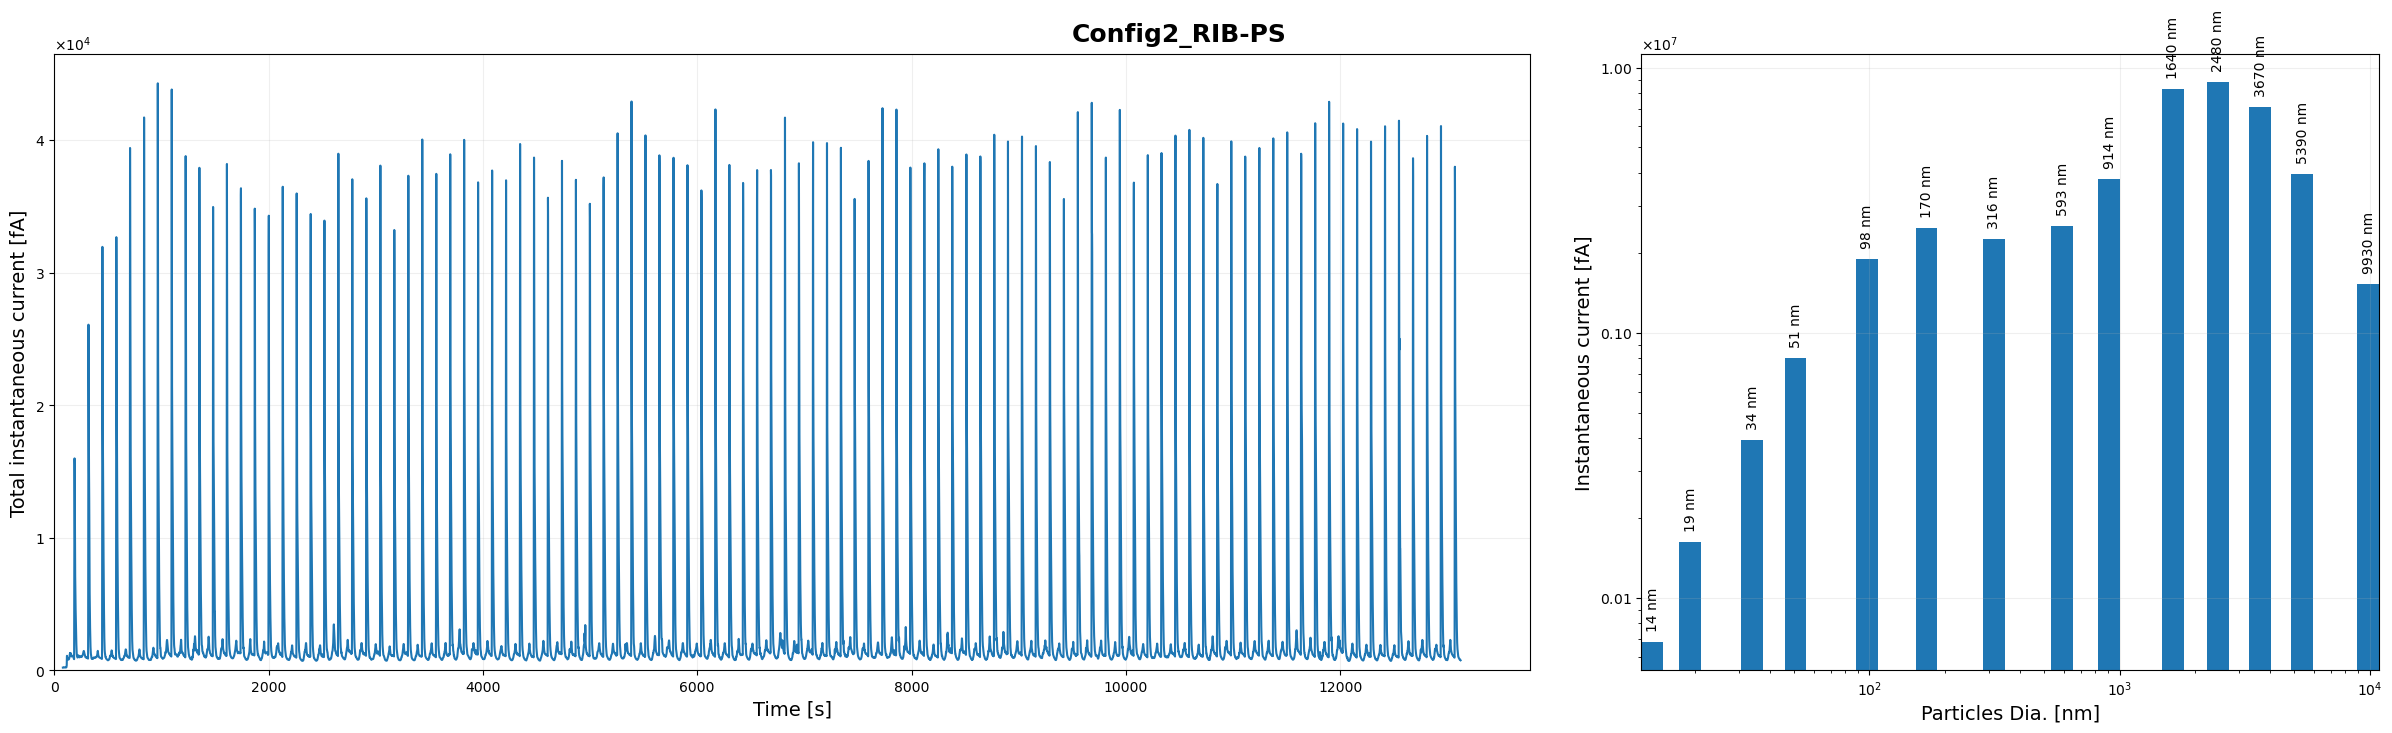

In [151]:
fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw={'width_ratios':(1,0.5), 'wspace':0.1})
fig.set_size_inches(w=30, h=8)

fig.suptitle(f"{n}", y=0.92, fontweight='bold')

ax1.plot(extrait_physical_data['Time [s]'], extrait_physical_data[extrait_physical_data.columns[1:-1]].sum(axis=1))
ax1.set_ylabel('Total instantaneous current [fA]')
ax1.set_xlabel('Time [s]')
ax1.grid(alpha=0.2)
ax1.set_xlim(left=0)
ax1.set_ylim(bottom=0)
ax1.margins(x=0)
# ax1.set_xlim(200,2000)


# Pour l'axe y de ax1 en notation scientifique
ax1.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax1.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

ax2.bar(extrait_physical_data.columns[1:-1].astype(float)*1000, height= extrait_physical_data[extrait_physical_data.columns[1:-1]].sum(axis=0),width=1000* extrait_physical_data.columns[1:-1].astype(float)/5 )
ax2.set_xscale('log')
ax2.set_xmargin(0)
ax2.grid(alpha=0.2)
ax2.set_ylabel('Instantaneous current [fA]')
ax2.set_xlabel('Particles Dia. [nm]')
ax2.set_yscale('log')
# Pour l'axe y de ax2 en notation scientifique
ax2.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# Ajout des étiquettes de diamètre sur chaque barre
for bar, diameter in zip(ax2.patches, extrait_physical_data.columns[1:-1].astype(float) * 1000):
    height = bar.get_height()
    if height > 0:  # éviter log(0)
        ax2.text(
            bar.get_x() + bar.get_width()/2,
            height * 1.1,
            f"{diameter:.0f} nm",
            ha='center',
            va='bottom',
            fontsize=10,
            rotation=90
        )

##### Plot: Extracted Total number concentration [#/cm3] vs time

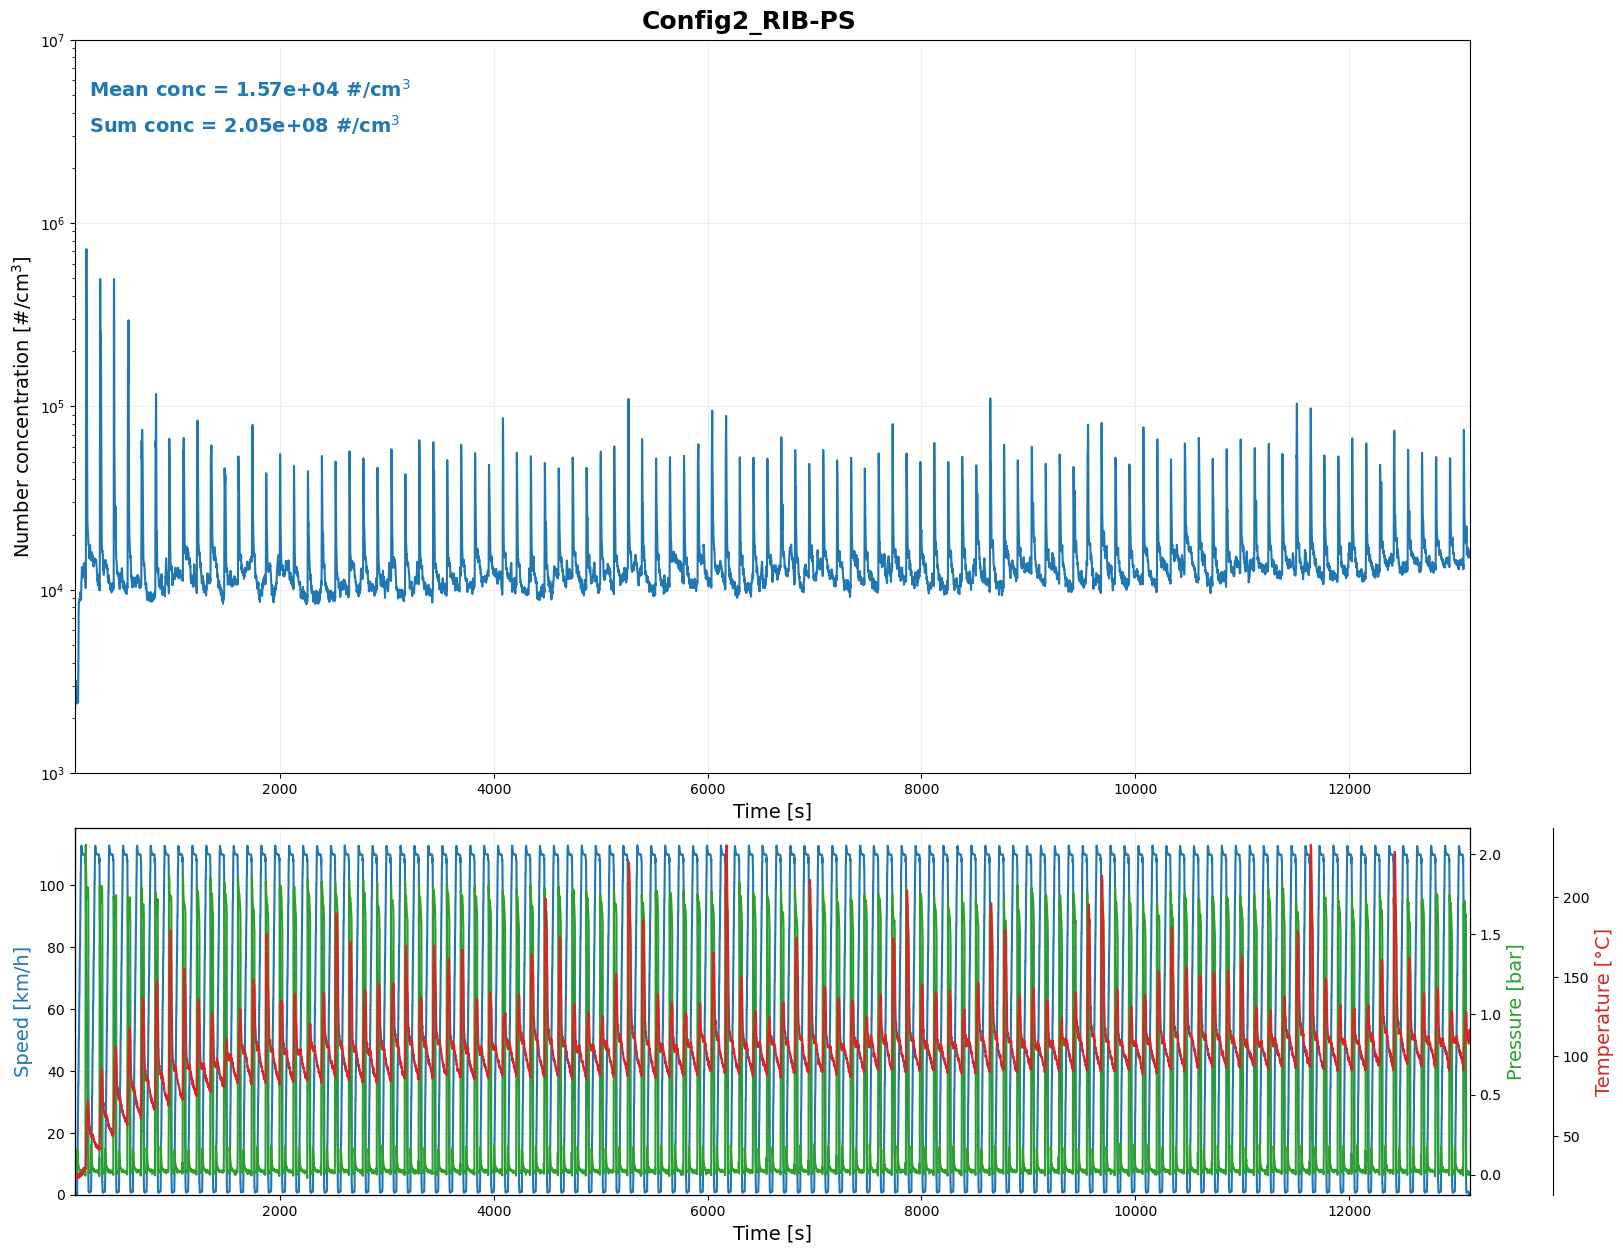

In [152]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)
fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# Limit of x-axis
time_min = lmin
time_max = lmax

# Plot number concentration
ax1.set_xlim(time_min, time_max)
ax1.plot(extrait_data['Time [s]'], extrait_data[extrait_data.columns[4]])
ax1.set_ylabel('Number concentration [#/cm$^3$]')
ax1.set_xlabel('Time [s]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E3, top=1E7)
# ax1.set_ylim(bottom=1E3, top=8E5)

# Annotate mean and sum on the plot
mean_value = extrait_data[extrait_data.columns[4]].mean()
sum_value = extrait_data[extrait_data.columns[4]].sum()
ax1.text(0.01, 0.95, f'Mean conc = {mean_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

# Plot Speed, Pressure, Temperature
ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()
ax2.set_xlim(time_min, time_max)
ax2.plot(extrait_data['Time [s]'], extrait_data['Speed']*(80/500), color='tab:blue') # RPM -> km/h
ax2_1.plot(extrait_data['Time [s]'], extrait_data['Pressure'], color='tab:green')
ax2_2.plot(extrait_data['Time [s]'], extrait_data['Temperature'], color='tab:red')
ax2.margins(x=0)
ax2.set_ylim(bottom=0)
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2.set_xlabel('Time [s]')
ax2.grid(alpha=0.2)

plt.show()

##### Plot: Extracted Total normalized number concentration [#/cm3] vs time

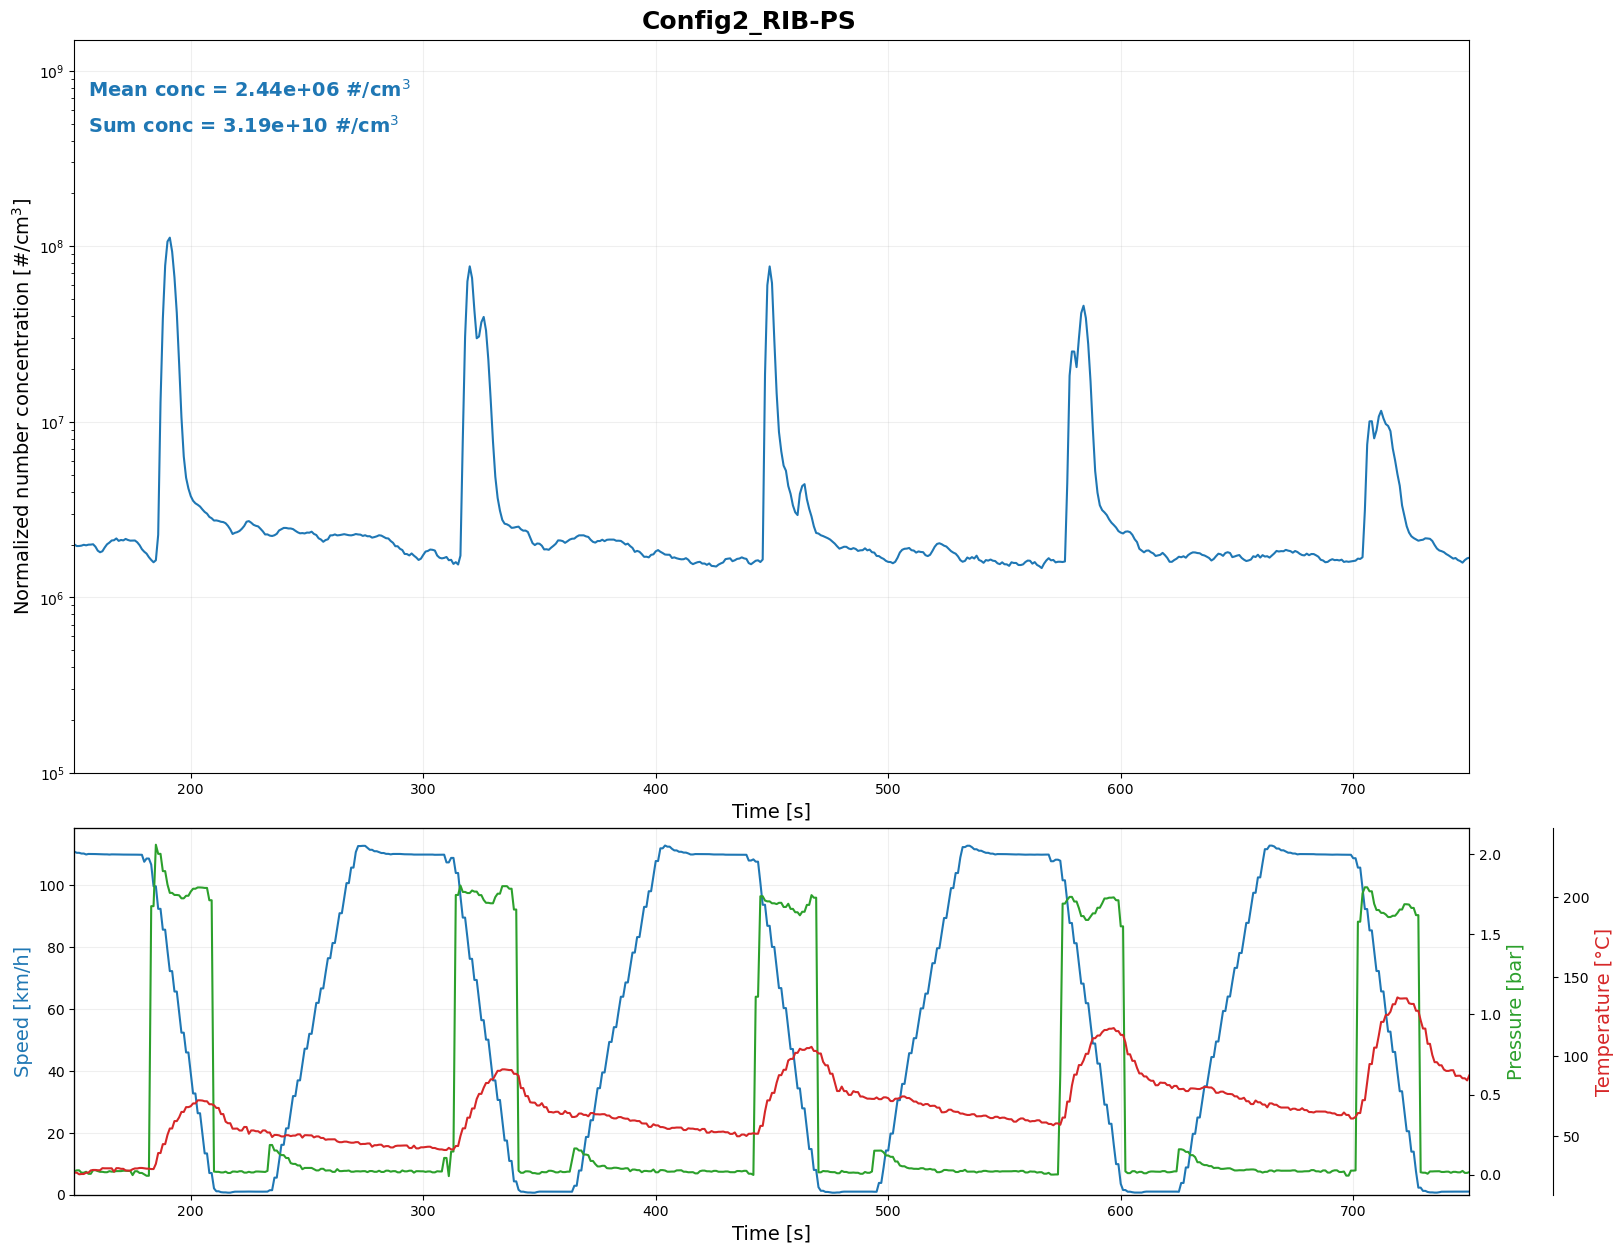

In [153]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)
fig.suptitle(f"{n}", y=0.9, fontweight='bold')

# Limit of x-axis
# time_min = lmin
# time_max = lmax

time_min = 150
time_max = 750

# Plot total normalized concentration
total_normalized_concentration = extrait_data.iloc[:, 5:-1].sum(axis=1)
ax1.plot(extrait_data['Time [s]'], total_normalized_concentration)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Normalized number concentration [#/cm$^3$]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E5, top=1.5E9)
# ax1.set_ylim(bottom=0, top=5.5E8)
ax1.set_xlim(time_min, time_max)

# Annotate mean and sum on the plot
mean_value_normalized = extrait_data.iloc[:, 5:-1].sum(axis=1).mean()
sum_value_normalized = extrait_data.iloc[:, 5:-1].sum(axis=1).sum()
ax1.text(0.01, 0.95, f'Mean conc = {mean_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

# Plot Speed, Pressure, Temperature
ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()
ax2.plot(extrait_data['Time [s]'], extrait_data['Speed']*(80/500), color='tab:blue')
ax2_1.plot(extrait_data['Time [s]'], extrait_data['Pressure'], color='tab:green')
ax2_2.plot(extrait_data['Time [s]'], extrait_data['Temperature'], color='tab:red')
ax2.set_xlabel('Time [s]')
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')   
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2.margins(x=0)
ax2.grid(alpha=0.2)
ax2.set_xlim(time_min, time_max)
ax2.set_ylim(bottom=0)

plt.show()

##### Modes: Total normalized number concentration vs Dp

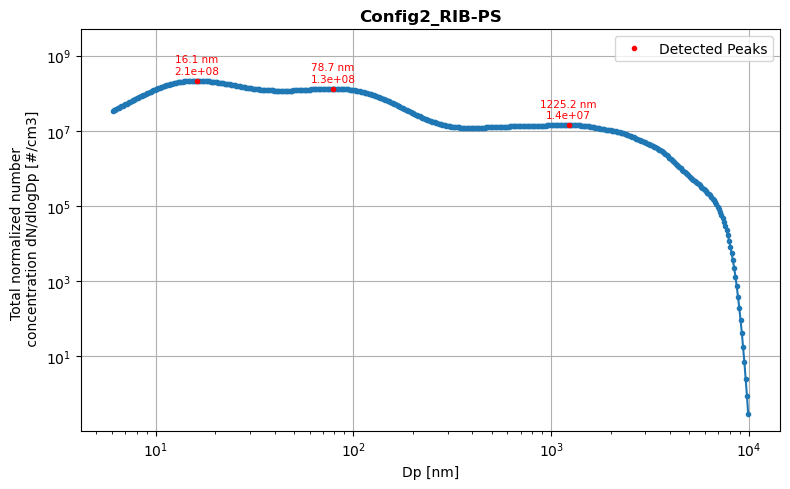

In [154]:
# Sum across diameter channels
somme_lignes = extrait_data.iloc[:, 5:-1].sum(axis=0) 
diameters = somme_lignes.index.astype(float) * 1000 

# Detect peaks
peaks, _ = find_peaks(somme_lignes.values)
peak_diameters = diameters[peaks]
peak_concentrations = somme_lignes.values[peaks]

# Plot 
plt.figure(figsize=(8, 5))
plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# Annotate peaks
for dp, conc in zip(peak_diameters, peak_concentrations):
    plt.annotate(f"{dp:.1f} nm\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
                 textcoords='offset points', ha='center', fontsize=7.5, color='red')

plt.title(f"{n}", fontsize=12)
plt.xscale('log')
plt.yscale('log')
plt.ylim(0,5e9)
plt.xlabel("Dp [nm]", fontsize=10)
plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm3]", fontsize=10)
plt.margins(y=0)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Next parts are dedicated only for RIB-PS tests

##### Correction code for number and normalized number concentration (#/cm3)

In [155]:
skip_after_braking = 25 # seconds to skip after braking
# Extract relevant columns
VPT = extrait_data[['Speed', 'Pressure', 'Temperature']] 
Time = extrait_data.iloc[:, -1:] 

# Detect braking phases
braking_start= np.array([])
braking_end= np.array([])
for i in range(1,len(VPT)):
    if (VPT['Pressure'].iloc[i]>1) & (VPT['Pressure'].iloc[i-1]<1):
        braking_start = np.append(braking_start,i)
    elif (VPT['Pressure'].iloc[i]<1) & (VPT['Pressure'].iloc[i-1]>1):
        braking_end = np.append(braking_end,i)

braking_start = np.array(braking_start)
braking_end = np.array(braking_end)

# Ensure each start has a corresponding end
if len(braking_start)> len(braking_end): 
    braking_start = braking_start[:-1]

# Build braking DataFrame
df_braking = pd.DataFrame()
df_braking['Braking'] = np.arange(1,len(braking_start)+1)
df_braking['Start'] = braking_start
df_braking['End'] = braking_end + skip_after_braking

df_braking['Duration_between'] = df_braking['Start'].shift(-1) - df_braking['End'] # Durée entre la fin d'un freinage et le début du suivant
for i in range(len(df_braking)): 
    if df_braking['Duration_between'].iloc[i]<0: # Si deux freinages se chevauchent, on réduit la fin du premier
        df_braking['End'].iloc[i] = df_braking['End'].iloc[i] - 25
    if i == len(df_braking)-1: # Pour le dernier freinage, on réduit la fin de dernier freinage de 20 secondes
        df_braking['End'].iloc[i] = df_braking['End'].iloc[i] - 20

df_braking.drop('Duration_between', axis=1, inplace=True)
df_braking=df_braking.astype(dtype=int)

# Read EP_Number and EP_Normalized
EP_Number = extrait_data.iloc[:, 4:5]
EP_Normalized = extrait_data.iloc[:, 5:-1]

# Correct EP_Number
EP_Number_corr = pd.DataFrame()
for i in tqdm(range(len(df_braking)),desc='Braking'):
    if i == 0:
        for j in np.arange(0,df_braking['End'].iloc[i]):
            d = pd.DataFrame(data=EP_Number.iloc[j]-EP_Number.iloc[0:df_braking['Start'].iloc[i]].mean())
            EP_Number_corr = pd.concat([EP_Number_corr,d.T],ignore_index=True)
    
    else:
        for j in np.arange(df_braking['End'].iloc[i-1],df_braking['End'].iloc[i]):
            d = pd.DataFrame(data=EP_Number.iloc[j]-EP_Number.iloc[df_braking['End'].iloc[i-1]:df_braking['Start'].iloc[i]].mean())
            EP_Number_corr = pd.concat([EP_Number_corr,d.T],ignore_index=True)
EP_Number_corr[EP_Number_corr < 0] = 0

# Correct EP_Normalized
EP_Normalized_corr = pd.DataFrame()
for i in tqdm(range(len(df_braking)),desc='Braking'):
    if i == 0:
        for j in np.arange(0,df_braking['End'].iloc[i]):
            d = pd.DataFrame(data=EP_Normalized.iloc[j]-EP_Normalized.iloc[0:df_braking['Start'].iloc[i]].mean())
            EP_Normalized_corr = pd.concat([EP_Normalized_corr,d.T],ignore_index=True)
    
    else:
        for j in np.arange(df_braking['End'].iloc[i-1],df_braking['End'].iloc[i]):
            d = pd.DataFrame(data=EP_Normalized.iloc[j]-EP_Normalized.iloc[df_braking['End'].iloc[i-1]:df_braking['Start'].iloc[i]].mean())
            EP_Normalized_corr = pd.concat([EP_Normalized_corr,d.T],ignore_index=True)
EP_Normalized_corr[EP_Normalized_corr < 0] = 0

# Add Time, Speed, Pressure to corrected DataFrames
EP_Number_corr = pd.concat([Time.iloc[:len(EP_Number_corr)].reset_index(drop=True), VPT.iloc[:len(EP_Number_corr)].reset_index(drop=True), EP_Number_corr["Total number"].reset_index(drop=True)], axis=1)
EP_Normalized_corr = pd.concat([Time.iloc[:len(EP_Normalized_corr)].reset_index(drop=True), VPT.iloc[:len(EP_Normalized_corr)].reset_index(drop=True), EP_Normalized_corr.iloc[:, 0:].reset_index(drop=True)], axis=1)

# Save corrected DataFrames
#Config1
# EP_Number_corr.to_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_RIB-PS\EP_Number_corr.csv", index=False)
# EP_Normalized_corr.to_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_RIB-PS\EP_Normalized_corr.csv", index=False)

#Config1_rep2
# EP_Number_corr.to_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_rep2_RIB-PS\EP_Number_corr.csv", index=False)
# EP_Normalized_corr.to_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_rep2_RIB-PS\EP_Normalized_corr.csv", index=False)

# Config2
# EP_Number_corr.to_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config2_RIB-PS\EP_Number_corr.csv", index=False)
# EP_Normalized_corr.to_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config2_RIB-PS\EP_Normalized_corr.csv", index=False)


output_folder = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data"

# Build file paths
ep_number_path = fr"{output_folder}\{n}\EP_Number_corr.csv"
ep_normalized_path = fr"{output_folder}\{n}\EP_Normalized_corr.csv"

# Save DataFrames
EP_Number_corr.to_csv(ep_number_path, index=False)
EP_Normalized_corr.to_csv(ep_normalized_path, index=False)


Braking: 100%|██████████| 100/100 [01:33<00:00,  1.07it/s]


### On a corrigé jusqu'au ici

##### Plot: Corrected Extracted Total number concentration [#/cm3] vs time

In [156]:
# Relecture des fichiers corrigés
#Config1
# EP_Number_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_RIB-PS\EP_Normalized_corr.csv")

#Config1_rep2
# EP_Number_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_rep2_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_rep2_RIB-PS\EP_Normalized_corr.csv")

# Config2
EP_Number_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config2_RIB-PS\EP_Number_corr.csv")
EP_Normalized_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config2_RIB-PS\EP_Normalized_corr.csv")

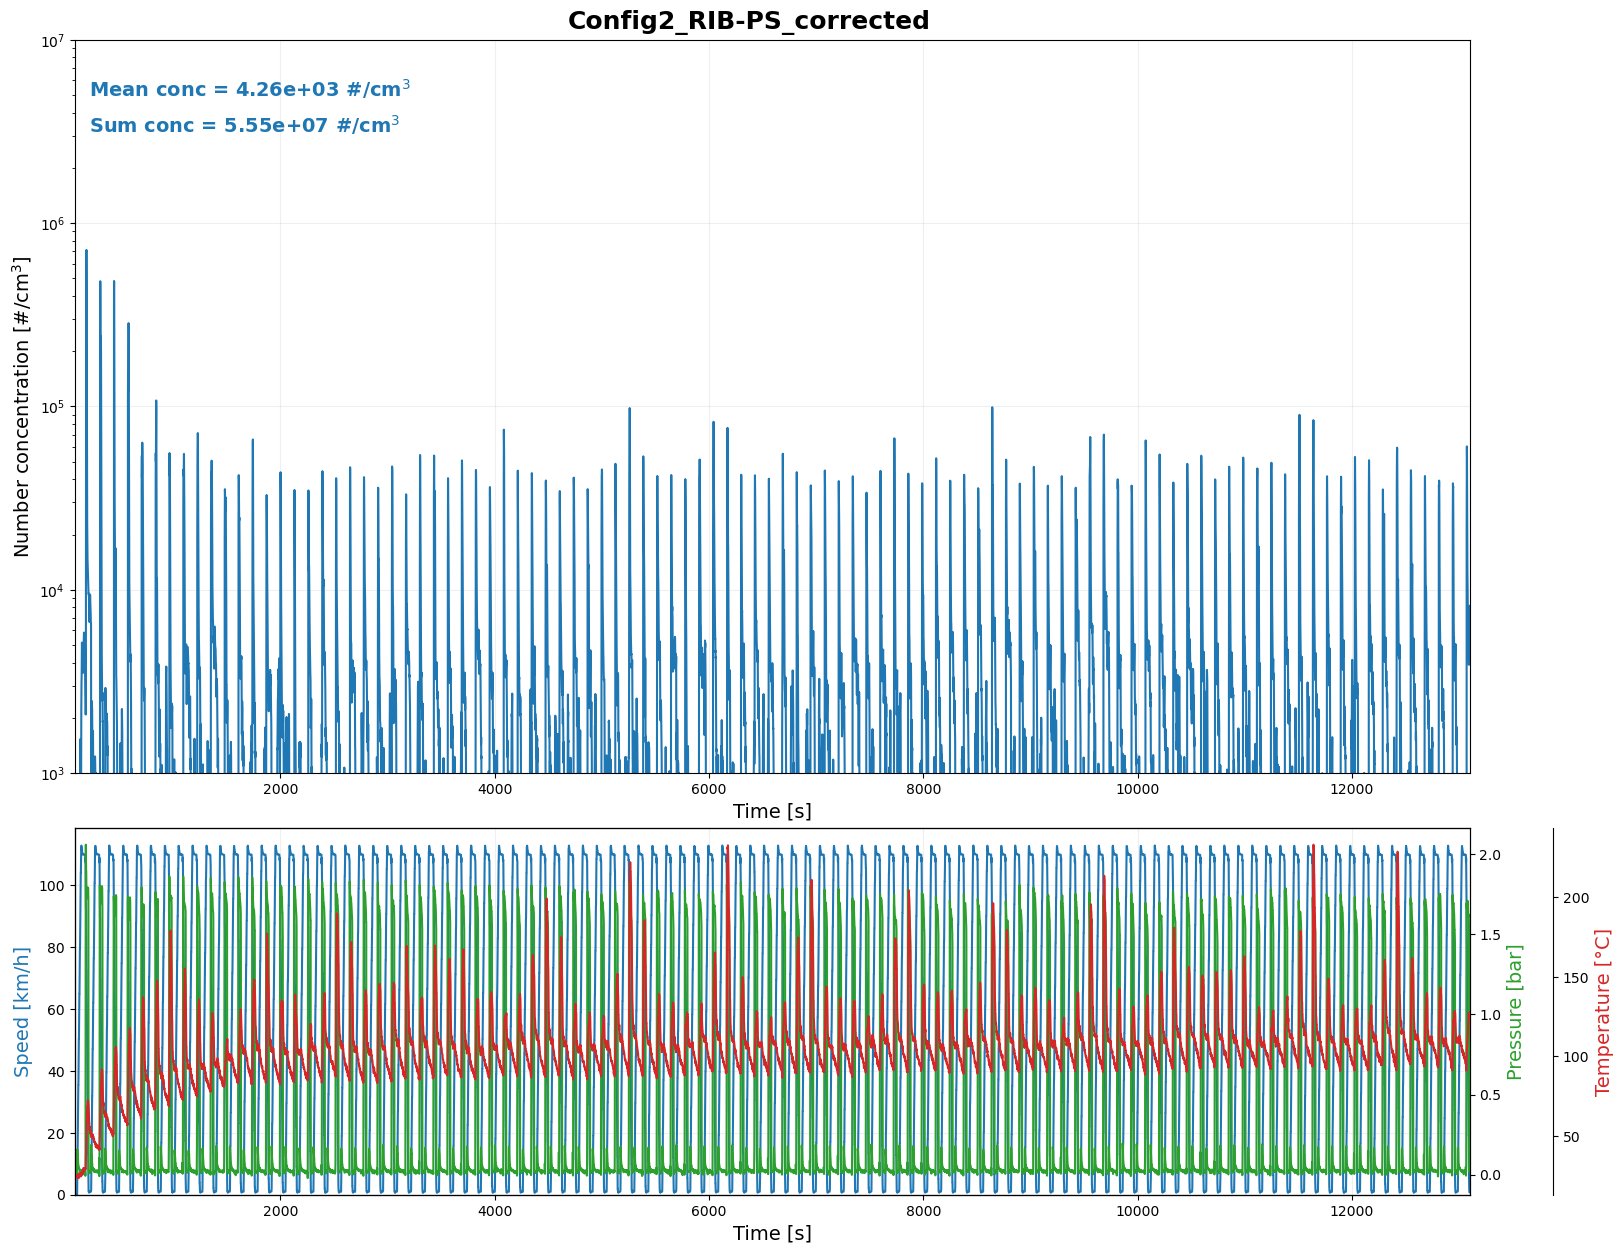

In [157]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)

fig.suptitle(f"{n}_corrected", y=0.9, fontweight='bold')

# Plot Total Number vs Time
time_min = EP_Number_corr['Time [s]'].iloc[0]
time_max = EP_Number_corr['Time [s]'].iloc[-1]
ax1.plot(EP_Number_corr['Time [s]'], EP_Number_corr["Total number"])
ax1.set_xlim(time_min, time_max)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Number concentration [#/cm$^3$]')
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E3, top=1E7)
ax1.grid(alpha=0.2)
ax1.margins(x=0)
# ax1.set_ylim(bottom=1E3, top=8E5)
# ax1.set_xlim(left=0)

# Annotate mean and sum
mean_value = EP_Number_corr["Total number"].mean()
sum_value = EP_Number_corr["Total number"].sum()
# Annotation en haut à gauche
ax1.text(0.01, 0.95, f'Mean conc = {mean_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

# Plot Speed, Pressure, Temperature on ax2
ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()

ax2.plot(EP_Number_corr['Time [s]'], EP_Number_corr['Speed']*(80/500), color='tab:blue') # RPM -> km/h
ax2_1.plot(EP_Number_corr['Time [s]'], EP_Number_corr['Pressure'], color='tab:green')
ax2_2.plot(EP_Number_corr['Time [s]'], EP_Number_corr['Temperature'], color='tab:red')
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2.grid(alpha=0.2)
ax2.set_xlim(time_min, time_max)
ax2.set_ylim(bottom=0)
ax2.margins(x=0)

plt.show()

##### Plot: Corrected Extracted Total normalized number concentration [#/cm3] vs time

(150.0, 750.0)

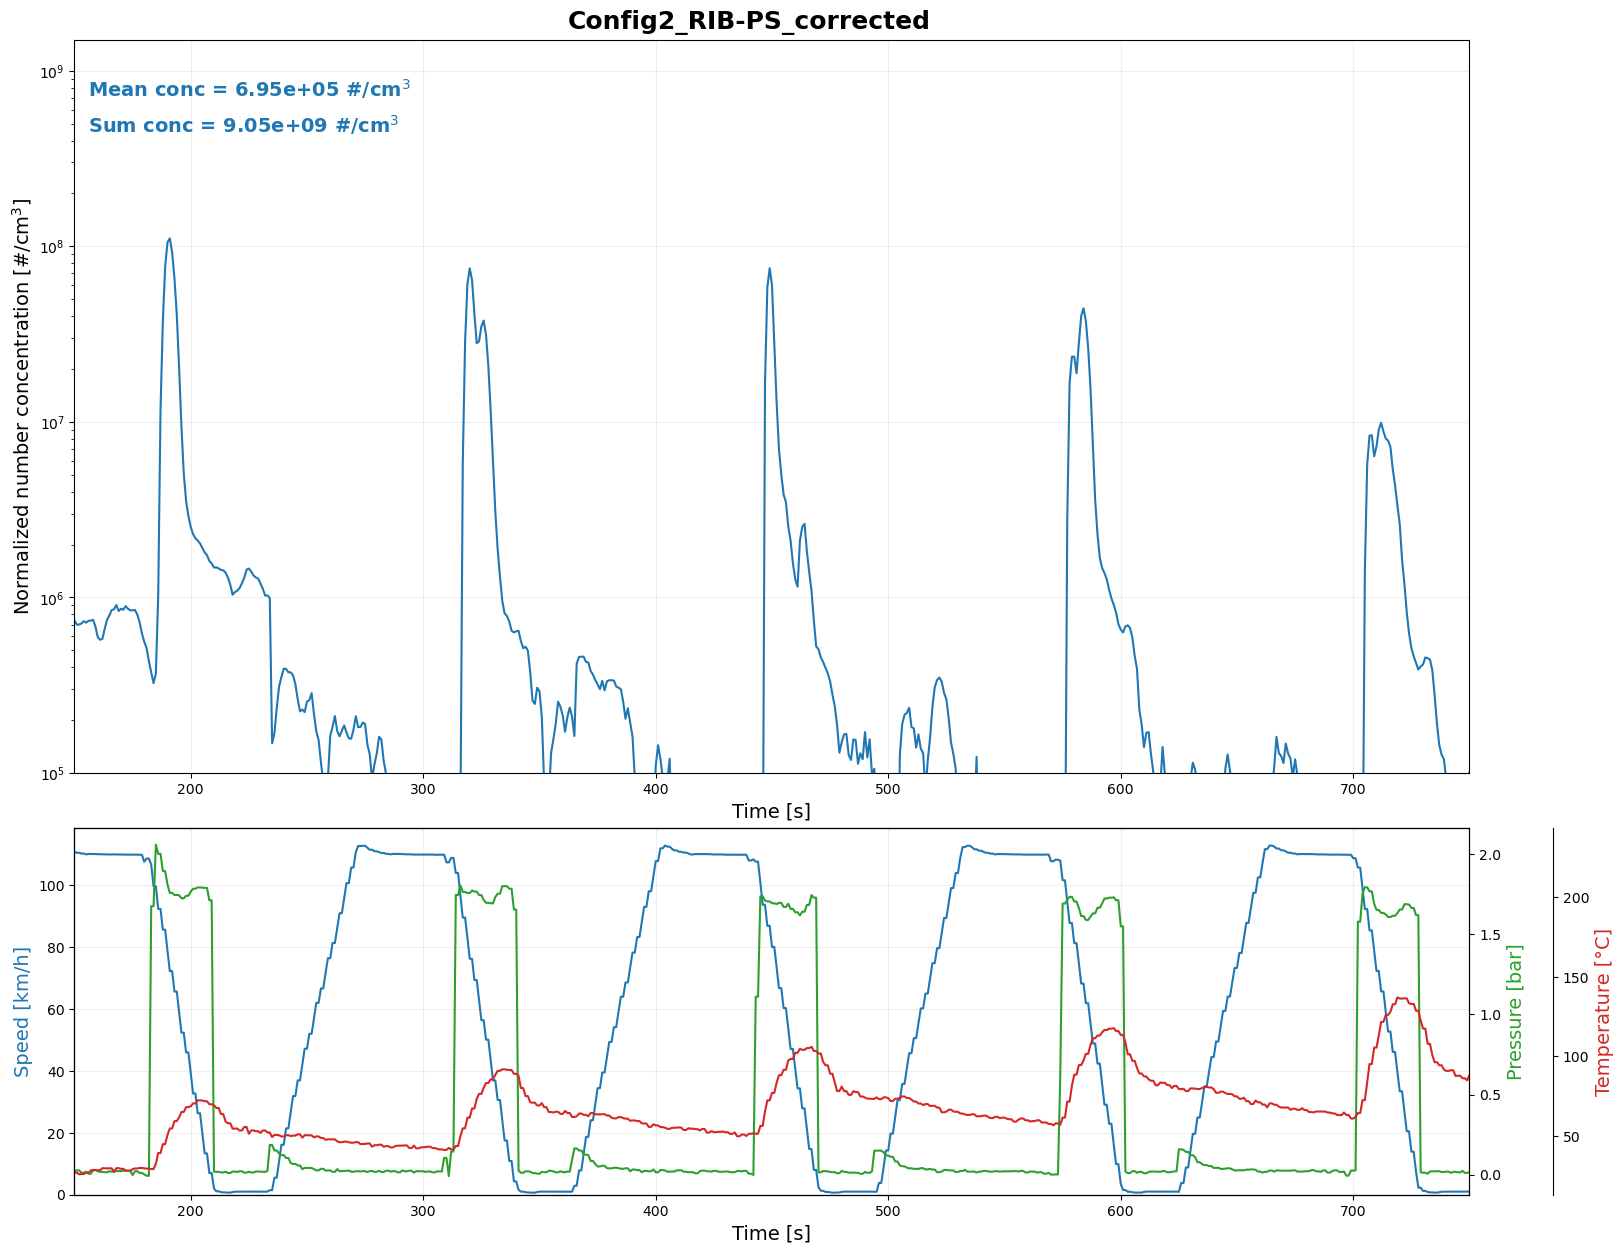

In [158]:
fig, (ax1, ax2)= plt.subplots(ncols=1,nrows=2, gridspec_kw={'height_ratios':(1,0.5), 'hspace':0.1})
fig.set_size_inches(w=18, h=15)

fig.suptitle(f"{n}_corrected", y=0.9, fontweight='bold')

# time_min = lmin
# time_max = lmax

time_min = 150
time_max = 750

total_normalized_concentration = EP_Normalized_corr.iloc[:, 4:].sum(axis=1)
ax1.plot(EP_Normalized_corr['Time [s]'], total_normalized_concentration)
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Normalized number concentration [#/cm$^3$]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)
ax1.set_xlim(left=0)
# ax1.set_ylim(bottom=0, top=5.5E8)
ax1.set_yscale('log')
ax1.set_ylim(bottom=1E5, top=1.5E9)
ax1.set_xlim(time_min, time_max)

# Calcul de la moyenne/somme
mean_value_normalized = EP_Normalized_corr.iloc[:, 4:].sum(axis=1).mean()
sum_value_normalized = EP_Normalized_corr.iloc[:, 4:].sum(axis=1).sum()
# Annotation en haut à gauche
ax1.text(0.01, 0.95, f'Mean conc = {mean_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')
ax1.text(0.01, 0.90, f'Sum conc = {sum_value_normalized:.2e} #/cm$^3$', transform=ax1.transAxes,
         fontsize=14, color='tab:blue', fontweight='bold',
         verticalalignment='top', horizontalalignment='left')

ax2_1 = ax2.twinx()
ax2_2 = ax2.twinx()

ax2.plot(EP_Normalized_corr['Time [s]'], EP_Normalized_corr['Speed']*(80/500), color='tab:blue')
ax2_1.plot(EP_Normalized_corr['Time [s]'], EP_Normalized_corr['Pressure'], color='tab:green')
ax2_2.plot(EP_Normalized_corr['Time [s]'], EP_Normalized_corr['Temperature'], color='tab:red')
ax2.set_xlabel('Time [s]')
ax2_2.spines['right'].set_position(('outward', 60))  # déplace le troisième axe y vers l'extérieur
ax2_2.set_ylabel('Temperature [°C]', color='tab:red')
ax2_1.set_ylabel('Pressure [bar]', color='tab:green')   
ax2.set_ylabel('Speed [km/h]', color='tab:blue')
ax2.margins(x=0)
ax2.grid(alpha=0.2)
ax2.set_xlim(left=0)
ax2.set_ylim(bottom=0)
ax2.set_xlim(time_min, time_max)
# ax1.set_ylim(0,1E6)
# ax1.set_yscale('log')

##### Modes: Corrected Total normalized number concentration vs Dp

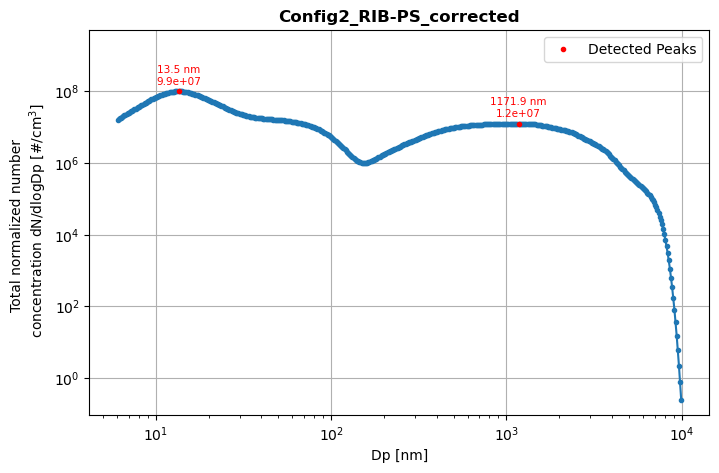

In [159]:
# Compute the sum of rows for each diameter channel
somme_lignes = EP_Normalized_corr.iloc[:, 4:].sum(axis=0) # Select all rows from columns 4 to the end and Sum across rows for each diameter channel
diameters = somme_lignes.index.astype(float) * 1000 # Convert to nm

# Detect all peaks in the summed extrait_data
peaks, _ = find_peaks(somme_lignes.values)

# Extract peak diameters and concentrations
peak_diameters = diameters[peaks]
peak_concentrations = somme_lignes.values[peaks]

# Plot the curve and all detected peaks
plt.figure(figsize=(8, 5))
plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# Annotate each peak
for dp, conc in zip(peak_diameters, peak_concentrations):
    plt.annotate(f"{dp:.1f} nm\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
                 textcoords='offset points', ha='center', fontsize=7.5, color='red')

plt.title(f"{n}_corrected", fontsize=12)
plt.xscale('log')
plt.yscale('log')
plt.ylim(0,5e9)
plt.xlabel("Dp [nm]", fontsize=10)
plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
plt.margins(y=0)
plt.grid(True)
plt.legend()
plt.show()